Notebook 05 - Trading Signals and Backtesting

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AI_Trading_Dissertation"
FINAL_PROJECT_PATH = PROJECT_PATH + "/Final_Project"

RESULTS_PATH = FINAL_PROJECT_PATH + "/04_Results"
PREDICTIONS_PATH = RESULTS_PATH + "/Predictions"
BENCHMARK_PATH = FINAL_PROJECT_PATH + "/02_Data/Processed/Benchmark"
FIGURES_PATH = FINAL_PROJECT_PATH + "/05_Figures"

os.makedirs(FIGURES_PATH, exist_ok=True)

# Backtest configuration

# Cost per SIDE, in basis points (1 bp = 0.01%). A round trip costs twice of this. 5 bps per side = 0.10% round trip, a realistic Indian intraday estimate.
COST_LEVELS_BPS = [0, 2, 5, 10, 20]
PRIMARY_COST_BPS = 5      # the headline number

RISK_FREE_ANNUAL = 0.065  # ~6.5% India short-term rate, used for Sharpe

MODELS_TO_BACKTEST = [
    "Baseline_Random",
    "Baseline_Majority",
    "Baseline_Momentum",
    "RandomForest",
    "XGBoost",
]

SIGNAL_TO_POSITION = {"Buy": 1, "Hold": 0, "Sell": -1}

print("Reading predictions from:", PREDICTIONS_PATH)


Reading predictions from: /content/drive/MyDrive/AI_Trading_Dissertation/Final_Project/04_Results/Predictions


In [ ]:
pred_files = sorted(glob.glob(os.path.join(PREDICTIONS_PATH, "*_predictions.parquet")))
stock_names = [os.path.basename(f).replace("_predictions.parquet", "") for f in pred_files]

print("Stocks with predictions:", len(stock_names))
print(stock_names)

_sample = pd.read_parquet(pred_files[0])
print("\nColumns available:", _sample.columns.tolist())


Stocks with predictions: 10
['Eicher_Motors', 'HDFCB', 'Hindustan_Unilever', 'ICICIBC', 'INFOSYS', 'ITC', 'Mahindra_and_Mahindra', 'ONGC', 'Reliance', 'TCS']

Columns available: ['datetime', 'close', 'future_return', 'target_signal', 'pred_Baseline_Random', 'pred_Baseline_Majority', 'pred_Baseline_Momentum', 'pred_RandomForest', 'pred_XGBoost']


In [ ]:
# Measuring bars per year empirically from the test period
_s = _sample.copy()
_span_days = (_s["datetime"].max() - _s["datetime"].min()).days
_bars_per_calendar_day = len(_s) / _span_days
BARS_PER_YEAR = _bars_per_calendar_day * 365.25

print(f"Test period spans {_span_days} calendar days with {len(_s)} bars")
print(f"-> approx {BARS_PER_YEAR:.0f} bars per year (used for annualising Sharpe)")


Test period spans 770 calendar days with 14489 bars
-> approx 6873 bars per year (used for annualising Sharpe)


In [ ]:
def run_backtest(df, signal_column, cost_bps, bars_per_year=None):
    """
    df must contain: datetime, close, and the signal column.
    Returns (metrics_dict, per_bar_dataframe).
    """
    if bars_per_year is None:
        bars_per_year = BARS_PER_YEAR

    out = df[["datetime", "close"]].copy()

    # The actual market return of each bar (close-to-close)
    out["market_return"] = out["close"].pct_change()

    # Model's desired position, decided using information up to that bar's close
    desired_position = df[signal_column].map(SIGNAL_TO_POSITION).fillna(0)

    # RULE 1: you can only act on the NEXT bar
    # Shifting forward by 1 means the position decided at bar t is applied to
    # bar t+1's return. Removing this shift and the backtest becomes fiction.
    out["position"] = desired_position.shift(1).fillna(0)

    # RULE 2: charge cost whenever the position changes
    # Going from 0 -> +1 is one unit of turnover. Going +1 -> -1 is two units
    # (close the long, open the short), so it costs twice as much. abs(diff)
    # captures that correctly.
    out["turnover"] = out["position"].diff().abs().fillna(out["position"].abs())
    cost_per_unit = cost_bps / 10000.0
    out["cost"] = out["turnover"] * cost_per_unit

    # Gross = what the position earned before costs. Net = after costs.
    out["strategy_return_gross"] = out["position"] * out["market_return"]
    out["strategy_return_net"] = out["strategy_return_gross"] - out["cost"]

    out = out.dropna(subset=["market_return"]).reset_index(drop=True)

    # Compound the returns into equity curves (start at 1.0 = 100% of capital)
    out["equity_strategy"] = (1 + out["strategy_return_net"]).cumprod()
    out["equity_buy_hold"] = (1 + out["market_return"]).cumprod()

    # metrics
    total_return = out["equity_strategy"].iloc[-1] - 1
    buy_hold_return = out["equity_buy_hold"].iloc[-1] - 1

    n_bars = len(out)
    years = n_bars / bars_per_year

    # CAGR - guard against the degenerate case of a wiped-out equity curve
    final_equity = out["equity_strategy"].iloc[-1]
    if final_equity > 0 and years > 0:
        cagr = final_equity ** (1 / years) - 1
    else:
        cagr = np.nan

    bh_final = out["equity_buy_hold"].iloc[-1]
    bh_cagr = bh_final ** (1 / years) - 1 if bh_final > 0 and years > 0 else np.nan

    # Sharpe: excess return over risk-free, per bar, scaled up to annual
    rf_per_bar = RISK_FREE_ANNUAL / bars_per_year
    excess = out["strategy_return_net"] - rf_per_bar
    sharpe = (excess.mean() / excess.std()) * np.sqrt(bars_per_year) if excess.std() > 0 else np.nan

    bh_excess = out["market_return"] - rf_per_bar
    bh_sharpe = (bh_excess.mean() / bh_excess.std()) * np.sqrt(bars_per_year) if bh_excess.std() > 0 else np.nan

    # Max drawdown: worst peak-to-trough fall in the equity curve
    running_peak = out["equity_strategy"].cummax()
    drawdown = out["equity_strategy"] / running_peak - 1
    max_drawdown = drawdown.min()

    bh_peak = out["equity_buy_hold"].cummax()
    bh_max_drawdown = (out["equity_buy_hold"] / bh_peak - 1).min()

    # Trade accounting
    n_position_changes = int((out["turnover"] > 0).sum())
    total_cost_paid = out["cost"].sum()
    time_in_market = (out["position"] != 0).mean()

    traded_bars = out[out["position"] != 0]
    win_rate = (traded_bars["strategy_return_gross"] > 0).mean() if len(traded_bars) > 0 else np.nan

    metrics = {
        "Total_Return": round(total_return, 4),
        "CAGR": round(cagr, 4) if not np.isnan(cagr) else np.nan,
        "Sharpe": round(sharpe, 3) if not np.isnan(sharpe) else np.nan,
        "Max_Drawdown": round(max_drawdown, 4),
        "BuyHold_Return": round(buy_hold_return, 4),
        "BuyHold_CAGR": round(bh_cagr, 4) if not np.isnan(bh_cagr) else np.nan,
        "BuyHold_Sharpe": round(bh_sharpe, 3) if not np.isnan(bh_sharpe) else np.nan,
        "BuyHold_MaxDD": round(bh_max_drawdown, 4),
        "Excess_vs_BuyHold": round(total_return - buy_hold_return, 4),
        "Position_Changes": n_position_changes,
        "Total_Cost_Paid": round(total_cost_paid, 4),
        "Time_In_Market": round(time_in_market, 3),
        "Win_Rate": round(win_rate, 4) if not np.isnan(win_rate) else np.nan,
        "N_Bars": n_bars,
    }

    return metrics, out


In [ ]:
_test = pd.read_parquet(pred_files[0])[["datetime", "close"]].copy()
_test["market_return"] = _test["close"].pct_change()

# Oracle: knows the next bar's direction (uses future info ON PURPOSE, as a test only)
_test["oracle"] = np.where(_test["market_return"].shift(-1) > 0, "Buy", "Sell")
_test["inverse_oracle"] = np.where(_test["market_return"].shift(-1) > 0, "Sell", "Buy")
_test["always_hold"] = "Hold"

for name in ["oracle", "inverse_oracle", "always_hold"]:
    m, _ = run_backtest(_test, name, cost_bps=0)
    print(f"{name:16s} total_return={m['Total_Return']:>12.2f}  sharpe={m['Sharpe']}  changes={m['Position_Changes']}")

print("\nExpected: oracle hugely positive, inverse_oracle hugely negative, always_hold exactly 0.0")


oracle           total_return=1089952370428.70  sharpe=62.391  changes=7662
inverse_oracle   total_return=       -1.00  sharpe=-63.009  changes=7662
always_hold      total_return=        0.00  sharpe=-2314030704685491.5  changes=0

Expected: oracle hugely positive, inverse_oracle hugely negative, always_hold exactly 0.0


In [ ]:
all_backtest_rows = []
equity_curves = {}
# (stock, model) -> dataframe, kept for the primary cost level only

for stock in stock_names:
    df = pd.read_parquet(os.path.join(PREDICTIONS_PATH, f"{stock}_predictions.parquet"))
    print(f"\n{stock}  ({len(df)} test bars)")

    for model in MODELS_TO_BACKTEST:
        signal_col = f"pred_{model}"
        if signal_col not in df.columns:
            print(f"  !! {signal_col} not found, skipping")
            continue

        for cost_bps in COST_LEVELS_BPS:
            metrics, per_bar = run_backtest(df, signal_col, cost_bps)
            metrics.update({"Stock": stock, "Model": model, "Cost_BPS": cost_bps})
            all_backtest_rows.append(metrics)

            if cost_bps == PRIMARY_COST_BPS:
                equity_curves[(stock, model)] = per_bar
                print(f"  {model:20s} ret={metrics['Total_Return']:>8.2%}  "
                      f"vs B&H {metrics['BuyHold_Return']:>8.2%}  "
                      f"sharpe={metrics['Sharpe']}  maxDD={metrics['Max_Drawdown']:.2%}")

backtest_df = pd.DataFrame(all_backtest_rows)
column_order = ["Stock", "Model", "Cost_BPS"] + [c for c in backtest_df.columns if c not in {"Stock", "Model", "Cost_BPS"}]
backtest_df = backtest_df[column_order]

backtest_df.to_csv(os.path.join(RESULTS_PATH, "Backtest_Results_Full.csv"), index=False)
print(f"\n\nSaved {len(backtest_df)} backtest results.")



Eicher_Motors  (14489 test bars)
  Baseline_Random      ret= -99.82%  vs B&H   60.80%  sharpe=-13.456  maxDD=-99.82%
  Baseline_Majority    ret= -46.31%  vs B&H   60.80%  sharpe=-1.234  maxDD=-49.81%
  Baseline_Momentum    ret= -99.98%  vs B&H   60.80%  sharpe=-17.497  maxDD=-99.98%
  RandomForest         ret= -87.63%  vs B&H   60.80%  sharpe=-4.317  maxDD=-88.02%
  XGBoost              ret= -91.88%  vs B&H   60.80%  sharpe=-4.82  maxDD=-92.72%

HDFCB  (14587 test bars)
  Baseline_Random      ret= -99.86%  vs B&H  -10.16%  sharpe=-16.335  maxDD=-99.86%
  Baseline_Majority    ret= -10.21%  vs B&H  -10.16%  sharpe=-0.418  maxDD=-28.35%
  Baseline_Momentum    ret= -99.99%  vs B&H  -10.16%  sharpe=-24.647  maxDD=-99.99%
  RandomForest         ret= -83.76%  vs B&H  -10.16%  sharpe=-4.677  maxDD=-83.93%
  XGBoost              ret= -92.68%  vs B&H  -10.16%  sharpe=-6.118  maxDD=-92.70%

Hindustan_Unilever  (14578 test bars)
  Baseline_Random      ret= -99.84%  vs B&H  -12.94%  sharpe=-16.034

In [ ]:
primary = backtest_df[backtest_df["Cost_BPS"] == PRIMARY_COST_BPS]

headline = (
    primary.groupby("Model")[
        ["Total_Return", "CAGR", "Sharpe", "Max_Drawdown", "BuyHold_Return",
         "Excess_vs_BuyHold", "Win_Rate", "Position_Changes", "Time_In_Market"]
    ]
    .mean()
    .round(4)
    .sort_values("Sharpe", ascending=False)
)

headline.to_csv(os.path.join(RESULTS_PATH, "Backtest_Headline_Summary.csv"))
print(f"Averaged across all {len(stock_names)} stocks, at {PRIMARY_COST_BPS} bps per side:\n")
headline


Averaged across all 10 stocks, at 5 bps per side:



,Total_Return,CAGR,Sharpe,Max_Drawdown,BuyHold_Return,Excess_vs_BuyHold,Win_Rate,Position_Changes,Time_In_Market
Model,,,,,,,,,
Baseline_Majority,-0.0629,-0.0392,-0.3280,-0.3523,-0.0333,-0.0295,0.4731,1.0,1.0000
RandomForest,-0.7871,-0.5437,-4.1834,-0.8060,-0.0333,-0.7538,0.4728,3117.8,0.6577
XGBoost,-0.9113,-0.6869,-5.4525,-0.9146,-0.0333,-0.8780,0.4755,3568.6,0.8279
Baseline_Random,-0.9987,-0.9570,-15.7433,-0.9987,-0.0333,-0.9654,0.4732,9603.6,0.7203
Baseline_Momentum,-0.9998,-0.9827,-20.3409,-0.9998,-0.0333,-0.9665,0.4477,8357.7,0.9447


In [ ]:
cost_sensitivity = (
    backtest_df
    .groupby(["Model", "Cost_BPS"])["Total_Return"]
    .mean()
    .unstack()
    .round(4)
)

cost_sensitivity.columns = [f"{c}bps" for c in cost_sensitivity.columns]
cost_sensitivity.to_csv(os.path.join(RESULTS_PATH, "Backtest_Cost_Sensitivity.csv"))
print("Average total return by model and cost level:\n")
cost_sensitivity


Average total return by model and cost level:



,0bps,2bps,5bps,10bps,20bps
Model,,,,,
Baseline_Majority,-0.0624,-0.0626,-0.0629,-0.0633,-0.0643
Baseline_Momentum,-0.6226,-0.9820,-0.9998,-1.0000,-1.0000
Baseline_Random,-0.0067,-0.9308,-0.9987,-1.0000,-1.0000
RandomForest,1.0093,-0.2048,-0.7871,-0.9718,-0.9992
XGBoost,0.5432,-0.5144,-0.9113,-0.9943,-1.0000


In [ ]:
# Picking model that has the best average Sharpe
real_models = [m for m in MODELS_TO_BACKTEST if not m.startswith("Baseline")]
best_model = headline.loc[[m for m in headline.index if m in real_models]].index[0]
print("Best real model by average Sharpe:", best_model)

per_stock = primary[primary["Model"] == best_model][
    ["Stock", "Total_Return", "CAGR", "Sharpe", "Max_Drawdown",
     "BuyHold_Return", "BuyHold_Sharpe", "Excess_vs_BuyHold", "Win_Rate", "Position_Changes"]
].set_index("Stock").round(4)

per_stock.to_csv(os.path.join(RESULTS_PATH, f"Backtest_PerStock_{best_model}.csv"))
per_stock


Best real model by average Sharpe: RandomForest


,Total_Return,CAGR,Sharpe,Max_Drawdown,BuyHold_Return,BuyHold_Sharpe,Excess_vs_BuyHold,Win_Rate,Position_Changes
Stock,,,,,,,,,
Eicher_Motors,-0.8763,-0.6289,-4.317,-0.8802,0.6080,0.740,-1.4842,0.4835,3867
HDFCB,-0.8376,-0.5754,-4.677,-0.8393,-0.1016,-0.417,-0.7360,0.4700,2678
Hindustan_Unilever,-0.8723,-0.6211,-5.338,-0.8743,-0.1294,-0.464,-0.7429,0.4691,3503
ICICIBC,-0.8438,-0.5826,-5.400,-0.8528,0.2420,0.285,-1.0858,0.4625,2897
INFOSYS,-0.8934,-0.6513,-4.405,-0.9025,-0.2643,-0.606,-0.6291,0.4572,2831
ITC,-0.8299,-0.5655,-4.968,-0.8332,-0.2970,-1.045,-0.5328,0.4609,3480
Mahindra_and_Mahindra,-0.2548,-0.1294,-0.676,-0.3984,0.1990,0.218,-0.4538,0.4802,2392
ONGC,-0.8268,-0.5617,-3.377,-0.8286,-0.1072,-0.297,-0.7195,0.4831,3494
Reliance,-0.7478,-0.4769,-3.604,-0.7536,-0.1015,-0.444,-0.6463,0.4835,2843


the approach did not generalise uniformly across sectors.

Comparing against the NIFTY 50 benchmark

In [ ]:
nifty = pd.read_csv(os.path.join(BENCHMARK_PATH, "NIFTY50_Daily.csv"), parse_dates=["date"])

test_start = _sample["datetime"].min()
test_end = _sample["datetime"].max()

nifty_window = nifty[(nifty["date"] >= test_start) & (nifty["date"] <= test_end)].reset_index(drop=True)
nifty_return = nifty_window["close"].iloc[-1] / nifty_window["close"].iloc[0] - 1

print(f"Test window: {test_start.date()} to {test_end.date()}")
print(f"NIFTY 50 return over this window: {nifty_return:.2%}")
print(f"\nStrategy returns over the same window (avg across stocks, {PRIMARY_COST_BPS} bps):")
for model in MODELS_TO_BACKTEST:
    r = primary[primary["Model"] == model]["Total_Return"].mean()
    verdict = "beats" if r > nifty_return else "loses to"
    print(f"  {model:20s} {r:>8.2%}   ({verdict} NIFTY)")


Test window: 2024-06-20 to 2026-07-31
NIFTY 50 return over this window: 3.76%

Strategy returns over the same window (avg across stocks, 5 bps):
  Baseline_Random       -99.87%   (loses to NIFTY)
  Baseline_Majority      -6.29%   (loses to NIFTY)
  Baseline_Momentum     -99.98%   (loses to NIFTY)
  RandomForest          -78.71%   (loses to NIFTY)
  XGBoost               -91.13%   (loses to NIFTY)


Equity curve charts
One chart per stock for the best model: strategy versus buy-and-hold.

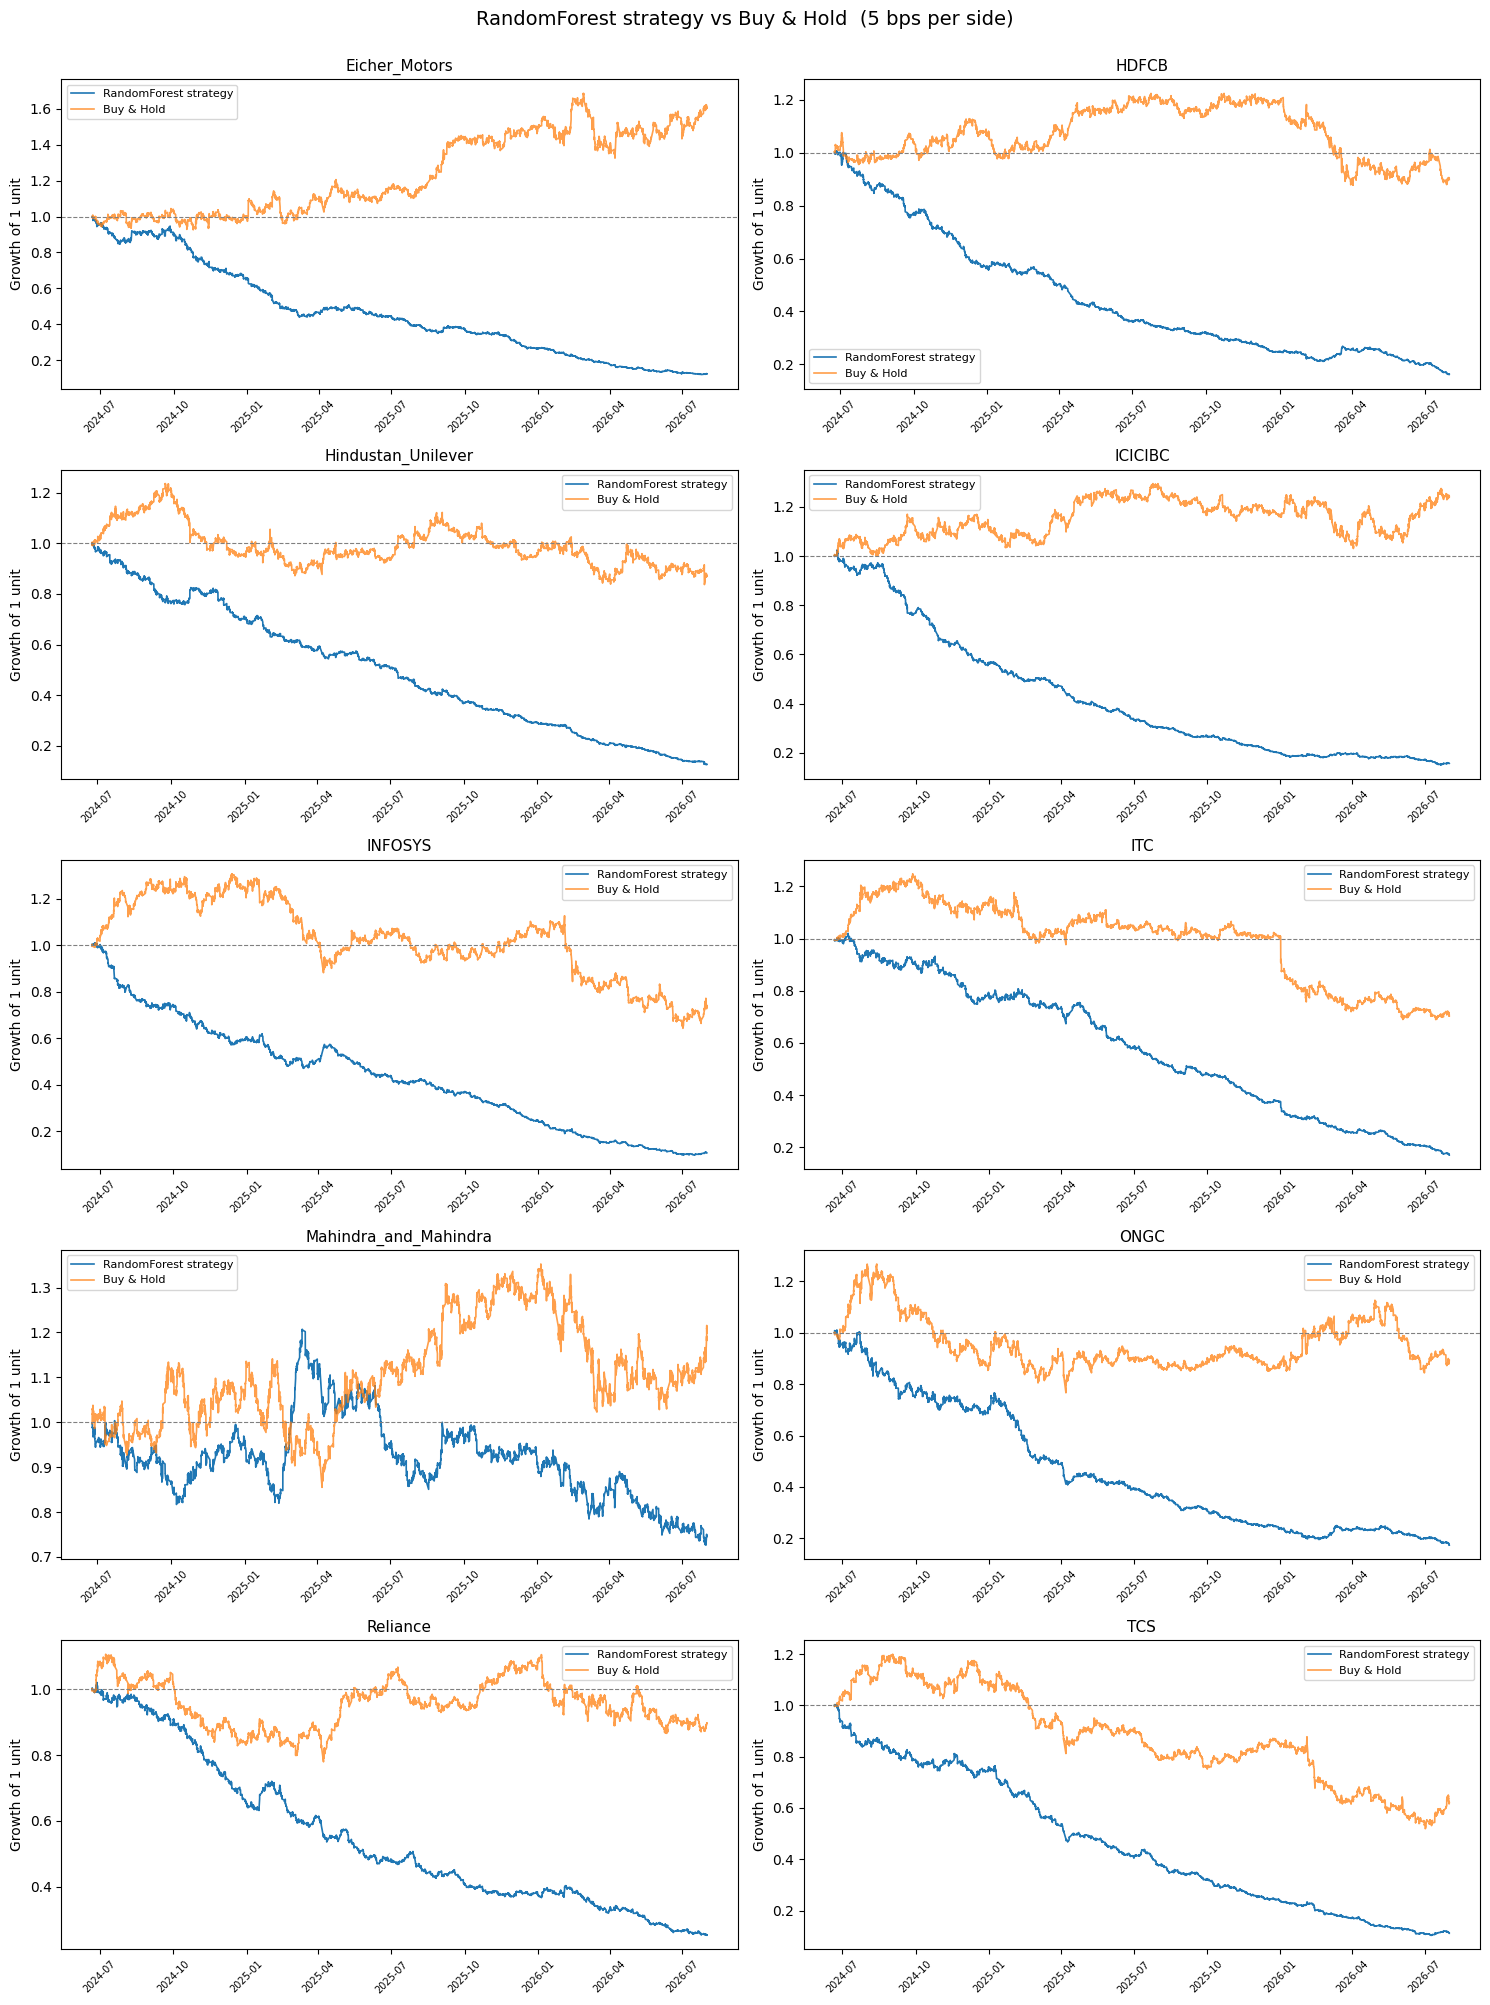

In [ ]:
n_stocks = len(stock_names)
fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.flatten()

for idx, stock in enumerate(stock_names):
    ax = axes[idx]
    curve = equity_curves.get((stock, best_model))
    if curve is None:
        continue

    ax.plot(curve["datetime"], curve["equity_strategy"], label=f"{best_model} strategy", linewidth=1.2)
    ax.plot(curve["datetime"], curve["equity_buy_hold"], label="Buy & Hold", linewidth=1.2, alpha=0.75)
    ax.axhline(1.0, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(stock, fontsize=11)
    ax.set_ylabel("Growth of 1 unit")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=45, labelsize=7)

for j in range(n_stocks, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f"{best_model} strategy vs Buy & Hold  ({PRIMARY_COST_BPS} bps per side)", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, f"equity_curves_{best_model}.png"), dpi=150, bbox_inches="tight")
plt.show()


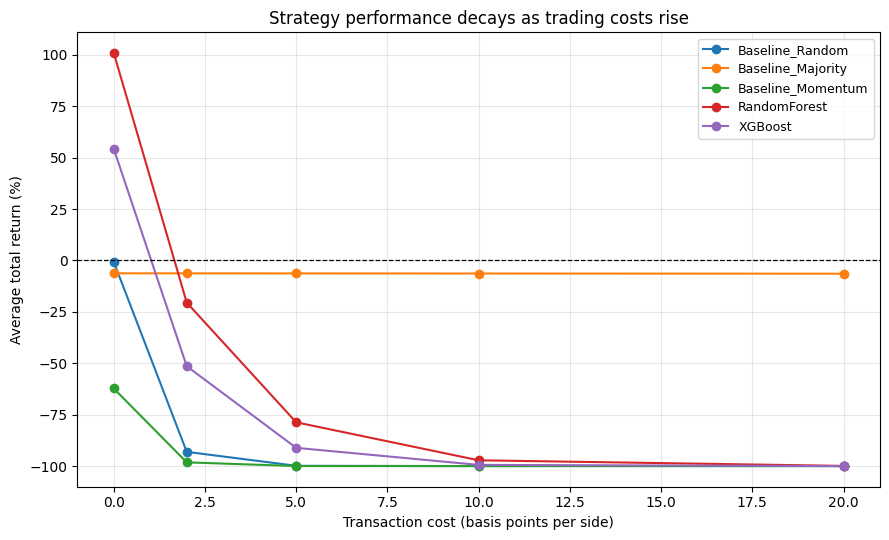

In [ ]:
# Cost sensitivity chart
fig, ax = plt.subplots(figsize=(9, 5.5))

for model in MODELS_TO_BACKTEST:
    series = backtest_df[backtest_df["Model"] == model].groupby("Cost_BPS")["Total_Return"].mean()
    ax.plot(series.index, series.values * 100, marker="o", label=model, linewidth=1.5)

ax.axhline(0, color="black", linewidth=0.9, linestyle="--")
ax.set_xlabel("Transaction cost (basis points per side)")
ax.set_ylabel("Average total return (%)")
ax.set_title("Strategy performance decays as trading costs rise")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "cost_sensitivity.png"), dpi=150, bbox_inches="tight")
plt.show()
